In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
train = pd.read_csv(r"C:\Projek\Machine Learning\portfolio\01\retail-sales-forecasting\data\train.csv")
stores = pd.read_csv(r"C:\Projek\Machine Learning\portfolio\01\retail-sales-forecasting\data\stores.csv")
oil = pd.read_csv(r"C:\Projek\Machine Learning\portfolio\01\retail-sales-forecasting\data\oil.csv")
holidays = pd.read_csv(r"C:\Projek\Machine Learning\portfolio\01\retail-sales-forecasting\data\holidays_events.csv")
transactions = pd.read_csv(r"C:\Projek\Machine Learning\portfolio\01\retail-sales-forecasting\data\transactions.csv")

In [4]:
dataframes = {
    "train": train,
    "stores": stores,
    "oil": oil,
    "holidays": holidays,
    "transactions": transactions
}

for name, df in dataframes.items():
    print(f"\n{name.upper()}")
    print("Shape:\n", df.shape)
    print("Columns:\n", df.columns.tolist())
    print("Missing values:\n", df.isnull().sum())
    


TRAIN
Shape:
 (3000888, 6)
Columns:
 ['id', 'date', 'store_nbr', 'family', 'sales', 'onpromotion']
Missing values:
 id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64

STORES
Shape:
 (54, 5)
Columns:
 ['store_nbr', 'city', 'state', 'type', 'cluster']
Missing values:
 store_nbr    0
city         0
state        0
type         0
cluster      0
dtype: int64

OIL
Shape:
 (1218, 2)
Columns:
 ['date', 'dcoilwtico']
Missing values:
 date           0
dcoilwtico    43
dtype: int64

HOLIDAYS
Shape:
 (350, 6)
Columns:
 ['date', 'type', 'locale', 'locale_name', 'description', 'transferred']
Missing values:
 date           0
type           0
locale         0
locale_name    0
description    0
transferred    0
dtype: int64

TRANSACTIONS
Shape:
 (83488, 3)
Columns:
 ['date', 'store_nbr', 'transactions']
Missing values:
 date            0
store_nbr       0
transactions    0
dtype: int64


In [5]:
for name, df in dataframes.items():
    print(f"\n{name.upper()}")
    print("Head:\n", df.head())


TRAIN
Head:
    id        date  store_nbr      family  sales  onpromotion
0   0  2013-01-01          1  AUTOMOTIVE    0.0            0
1   1  2013-01-01          1   BABY CARE    0.0            0
2   2  2013-01-01          1      BEAUTY    0.0            0
3   3  2013-01-01          1   BEVERAGES    0.0            0
4   4  2013-01-01          1       BOOKS    0.0            0

STORES
Head:
    store_nbr           city                           state type  cluster
0          1          Quito                       Pichincha    D       13
1          2          Quito                       Pichincha    D       13
2          3          Quito                       Pichincha    D        8
3          4          Quito                       Pichincha    D        9
4          5  Santo Domingo  Santo Domingo de los Tsachilas    D        4

OIL
Head:
          date  dcoilwtico
0  2013-01-01         NaN
1  2013-01-02       93.14
2  2013-01-03       92.97
3  2013-01-04       93.12
4  2013-01-07      

In [6]:
for name, df in dataframes.items():
    print(f"\n{name.upper()}")
    print("Data type:\n", df.dtypes)
    print("Describe:\n", df.describe())


TRAIN
Data type:
 id               int64
date               str
store_nbr        int64
family             str
sales          float64
onpromotion      int64
dtype: object
Describe:
                  id     store_nbr         sales   onpromotion
count  3.000888e+06  3.000888e+06  3.000888e+06  3.000888e+06
mean   1.500444e+06  2.750000e+01  3.577757e+02  2.602770e+00
std    8.662819e+05  1.558579e+01  1.101998e+03  1.221888e+01
min    0.000000e+00  1.000000e+00  0.000000e+00  0.000000e+00
25%    7.502218e+05  1.400000e+01  0.000000e+00  0.000000e+00
50%    1.500444e+06  2.750000e+01  1.100000e+01  0.000000e+00
75%    2.250665e+06  4.100000e+01  1.958473e+02  0.000000e+00
max    3.000887e+06  5.400000e+01  1.247170e+05  7.410000e+02

STORES
Data type:
 store_nbr    int64
city           str
state          str
type           str
cluster      int64
dtype: object
Describe:
        store_nbr    cluster
count  54.000000  54.000000
mean   27.500000   8.481481
std    15.732133   4.693395
min     

In [7]:
train['date'] = pd.to_datetime(train['date'])
oil['date'] = pd.to_datetime(oil['date'])
holidays['date'] = pd.to_datetime(holidays['date'])
transactions['date'] = pd.to_datetime(transactions['date'])

In [8]:
for name, df in dataframes.items():
    print(f"\n{name.upper()}")
    print("Data type:\n", df.dtypes)


TRAIN
Data type:
 id                      int64
date           datetime64[us]
store_nbr               int64
family                    str
sales                 float64
onpromotion             int64
dtype: object

STORES
Data type:
 store_nbr    int64
city           str
state          str
type           str
cluster      int64
dtype: object

OIL
Data type:
 date          datetime64[us]
dcoilwtico           float64
dtype: object

HOLIDAYS
Data type:
 date           datetime64[us]
type                      str
locale                    str
locale_name               str
description               str
transferred              bool
dtype: object

TRANSACTIONS
Data type:
 date            datetime64[us]
store_nbr                int64
transactions             int64
dtype: object


In [9]:
for name, df in dataframes.items():
    print(f"\n{name.upper()}")
    print("Duplicated rows:\n", df.duplicated().sum())
    print("Unique values:\n", df.nunique())


TRAIN
Duplicated rows:
 0
Unique values:
 id             3000888
date              1684
store_nbr           54
family              33
sales           379610
onpromotion        362
dtype: int64

STORES
Duplicated rows:
 0
Unique values:
 store_nbr    54
city         22
state        16
type          5
cluster      17
dtype: int64

OIL
Duplicated rows:
 0
Unique values:
 date          1218
dcoilwtico     998
dtype: int64

HOLIDAYS
Duplicated rows:
 0
Unique values:
 date           312
type             6
locale           3
locale_name     24
description    103
transferred      2
dtype: int64

TRANSACTIONS
Duplicated rows:
 0
Unique values:
 date            1682
store_nbr         54
transactions    4993
dtype: int64


tidak ada data duplikasi.
jumlah toko (store_nbr) ada 54.
jumlah kategori produk (family) ada 33.

In [10]:
for name, df in dataframes.items():
    print(f"\n{name.upper()}")
    print("missing values:\n", df.isnull().sum())


TRAIN
missing values:
 id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64

STORES
missing values:
 store_nbr    0
city         0
state        0
type         0
cluster      0
dtype: int64

OIL
missing values:
 date           0
dcoilwtico    43
dtype: int64

HOLIDAYS
missing values:
 date           0
type           0
locale         0
locale_name    0
description    0
transferred    0
dtype: int64

TRANSACTIONS
missing values:
 date            0
store_nbr       0
transactions    0
dtype: int64


tidak ada missing values.

In [11]:
print("Start date (train):", train["date"].min())
print("End date (train):", train["date"].max())

Start date (train): 2013-01-01 00:00:00
End date (train): 2017-08-15 00:00:00


DISTRIBUSI SALES

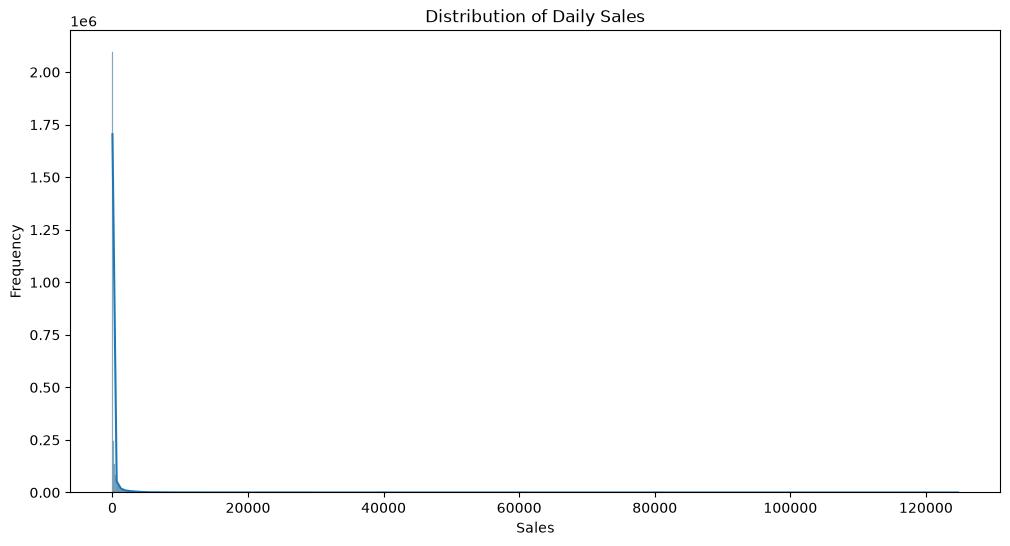

In [12]:
plt.figure(figsize=(12, 6))

sns.histplot(data=train, x='sales', bins=1000, kde=True)

plt.title('Distribution of Daily Sales')
plt.xlabel('Sales')
plt.ylabel('Frequency')
plt.show()

distribusi kebanyakan di nilai nol.

TREN PENJUALAN HARIAN

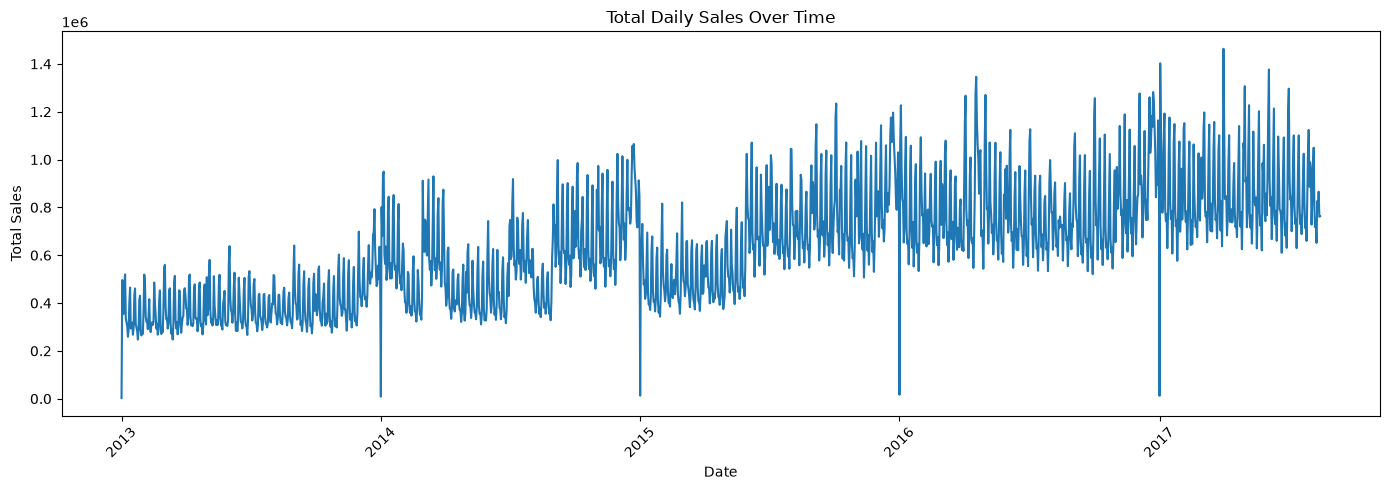

In [13]:
daily_sales = (
    train.groupby('date')['sales'].sum().reset_index()
)

plt.figure(figsize=(14, 5))
plt.plot(daily_sales['date'], daily_sales['sales'])

plt.title('Total Daily Sales Over Time')
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

terdapat tren kenaikan penjualan.
terdapat penurunan ekstrem.
kemungkinan terdapat pola musiman.

PENJUALAN BERDASARKAN PRODUK FAMILY

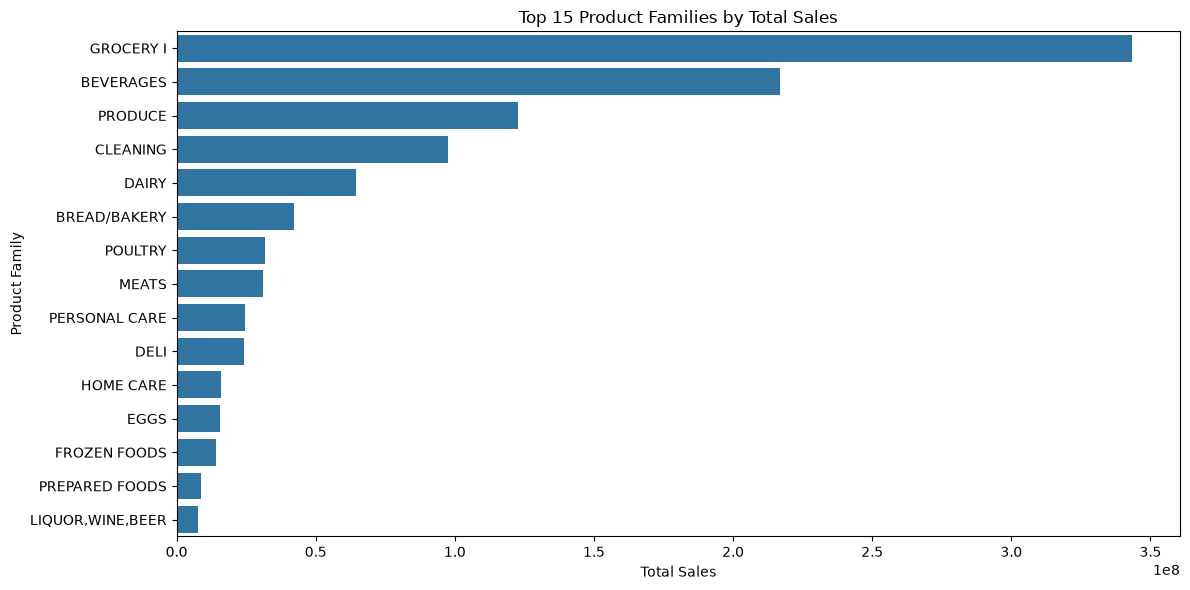

In [14]:
family_sales = (
    train.groupby('family')['sales'].sum().sort_values(ascending=False).reset_index()
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=family_sales.head(15),
    x='sales', 
    y='family'
)

plt.title('Top 15 Product Families by Total Sales')
plt.xlabel('Total Sales')
plt.ylabel('Product Family')
plt.tight_layout()
plt.show()

PENJUALAN BERDASARKAN HARI

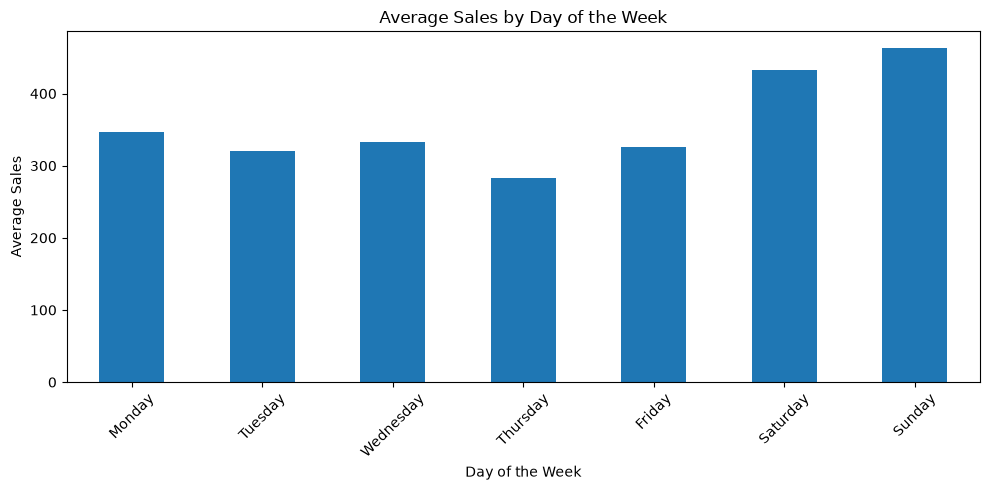

In [15]:
train['day_of_week'] = train['date'].dt.day_name()

weekday_sales = (
    train.groupby('day_of_week')['sales'].mean().reindex([
        'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'
    ])
)

weekday_sales.plot(
    kind='bar', 
    figsize=(10, 5)
)

plt.title('Average Sales by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Average Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

HUBUNGAN PROMOSI DAN PENJUALAN

In [16]:
promotion_sales = (
    train.groupby('onpromotion')['sales'].mean().reset_index()
)

promotion_sales.head(10)

,onpromotion,sales
0,0,158.246681
1,1,467.556532
2,2,662.925632
3,3,871.408092
4,4,969.916135
5,5,1010.659835
6,6,1022.854287
7,7,1022.567058
8,8,1174.757003
9,9,1258.733993


ada indikasi hubungan positif antara promosi dan penjualan

# EDA Findings

1. Sales Distribution
distribusi penjualan banyak berjumlah 0. 
interpretasi: Bisa menunjukkan tidak ada penjualan pada kombinasi produk dan tanggal tertentu

2. Sales Trend
tren penjualan cenderung naik dan kemungkinan memiliki pola musiman berdasarkan fluktuasi
interpretasi: menunjukkan peningkatan volume penjualan, tetapi juga mungkin dipengaruhi ekspansi toko atau faktor lain

3. Product Family Performance
top 5 produk family yaitu grocery I, beverages, produce, cleaning, dairy
interpretasi: Volume penjualan tidak merata antarproduk

4. Weekly Sales Pattern
rata-rata penjualan tertinggi di hari minggu dan terendah di hari kamis.
interpretasi: Ada variasi penjualan yang perlu dijelaskan lebih lanjut

5. Promotion Analysis
ada indikasi hubungan positif antara promosi dengan penjualan.
interpretasi: belum bisa menyimpulkan bahwa promosi menyebabkan peningkatan penjualan, bisa jadi ada faktor lain.

Business Implications
1. Perlu mempertimbangkan karakteristik zero sales ketika mengevaluasi model.
2. Perencanaan demand perlu mempertimbangkan perubahan level penjualan dari waktu ke waktu.
3. Prioritas monitoring dan perencanaan dapat dibedakan berdasarkan product family
4. Perusahaan membutuhkan prediksi yang mampu menangkap perubahan permintaan
5. Promosi berpotensi menjadi salah satu faktor yang perlu dipertimbangkan dalam perencanaan penjualan. Perlu analisis lebih lanjut untuk mengukur pengaruh promosi secara lebih akurat.


In [17]:
# Select top 5 product families
top_families = (
    train.groupby('family')['sales']
    .sum()
    .nlargest(5)
    .index
    .tolist()
)

print("Selected families: ")
print(top_families)

Selected families: 
['GROCERY I', 'BEVERAGES', 'PRODUCE', 'CLEANING', 'DAIRY']


In [18]:
model_data = (
    train[train['family'].isin(top_families)]
    .groupby(['date', 'family'], as_index=False)
    ['sales']
    .sum()
)

model_data.head(10)

,date,family,sales
0,2013-01-01,BEVERAGES,810.0
1,2013-01-01,CLEANING,186.0
2,2013-01-01,DAIRY,143.0
3,2013-01-01,GROCERY I,700.0
4,2013-01-01,PRODUCE,0.0
5,2013-01-02,BEVERAGES,72092.0
6,2013-01-02,CLEANING,74629.0
7,2013-01-02,DAIRY,23381.0
8,2013-01-02,GROCERY I,202020.0
9,2013-01-02,PRODUCE,0.0


In [19]:
print("Dataset shape:", model_data.shape)

print("\nMissing values:")
print(model_data.isnull().sum())

print("\nDate range:")
print(model_data["date"].min())
print(model_data["date"].max())

Dataset shape: (8420, 3)

Missing values:
date      0
family    0
sales     0
dtype: int64

Date range:
2013-01-01 00:00:00
2017-08-15 00:00:00


SIMPAN HASIL DATA PREPARATION

In [21]:
model_data.to_csv(
    r"C:\Projek\Machine Learning\portfolio\01\data\processed\daily_family_sales.csv",
    index=False
)
print("\nData saved to daily_family_sales.csv")


Data saved to daily_family_sales.csv


#FORECASTING APPROACH
1. Business problem: mengantisipasi penjualan retail dalam jangka pendek
2. Target variable: sales
3. Granularity: Daily Sales per Product Familiy
4. Scope: Top 5 Product Families
5. Horizon: 7 hari
6. Model: Random Forest Regressor
7. Baseline: Seasonal Naive
8. Validation: Chronological split
9. Evaluation: MAE, RMSE, WAPE

In [22]:
weekly_yearly = train.copy()

weekly_yearly["year"] = weekly_yearly["date"].dt.year
weekly_yearly["day_name"] = weekly_yearly["date"].dt.day_name()

weekly_yearly = (
    weekly_yearly.groupby(["year", "day_name"])["sales"]
    .mean()
    .reset_index()
)

weekly_pivot = weekly_yearly.pivot(
    index="day_name",
    columns="year",
    values="sales"
)

weekly_pivot = weekly_pivot.reindex([
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
])

weekly_pivot

year,2013,2014,2015,2016,2017
day_name,,,,,
Monday,211.242176,315.052475,355.767856,428.775885,465.263154
Tuesday,186.236645,291.040774,333.738206,399.179109,432.757792
Wednesday,192.269068,297.210268,348.224100,416.901180,454.808598
Thursday,173.584347,255.898034,294.777527,351.507165,377.217399
Friday,195.137239,285.060899,335.171226,406.874901,450.898361
Saturday,271.492429,392.823523,447.671006,528.008805,582.071919
Sunday,285.510812,422.698063,484.927234,576.935851,596.172174


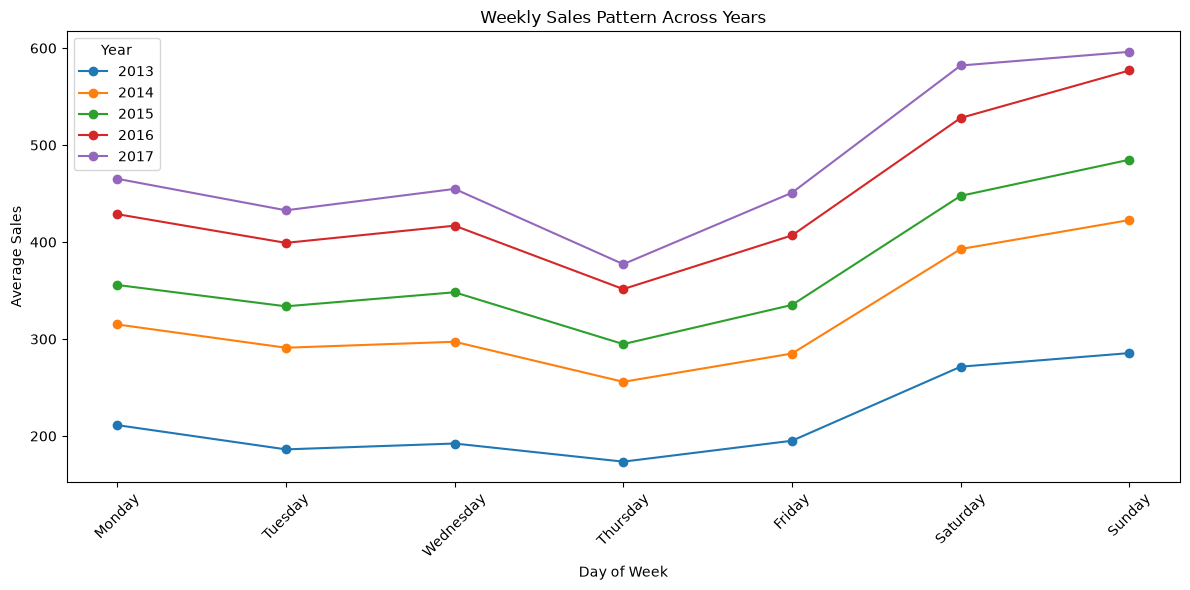

In [23]:
weekly_pivot.plot(
    kind="line",
    marker="o",
    figsize=(12, 6)
)

plt.title("Weekly Sales Pattern Across Years")
plt.xlabel("Day of Week")
plt.ylabel("Average Sales")
plt.xticks(rotation=45)
plt.legend(title="Year")
plt.tight_layout()
plt.show()

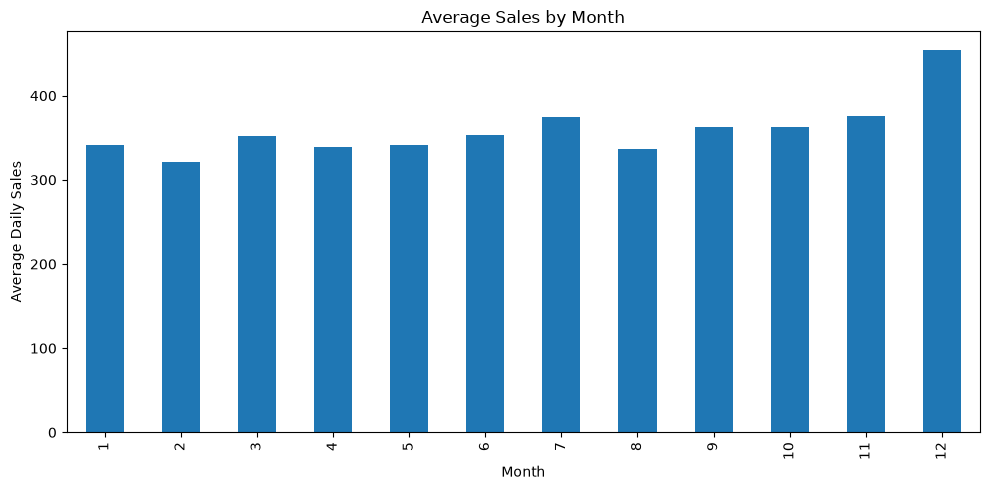

In [24]:
monthly_sales = (
    train.groupby(train["date"].dt.month)["sales"]
    .mean()
)

monthly_sales.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Average Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Daily Sales")
plt.tight_layout()
plt.show()

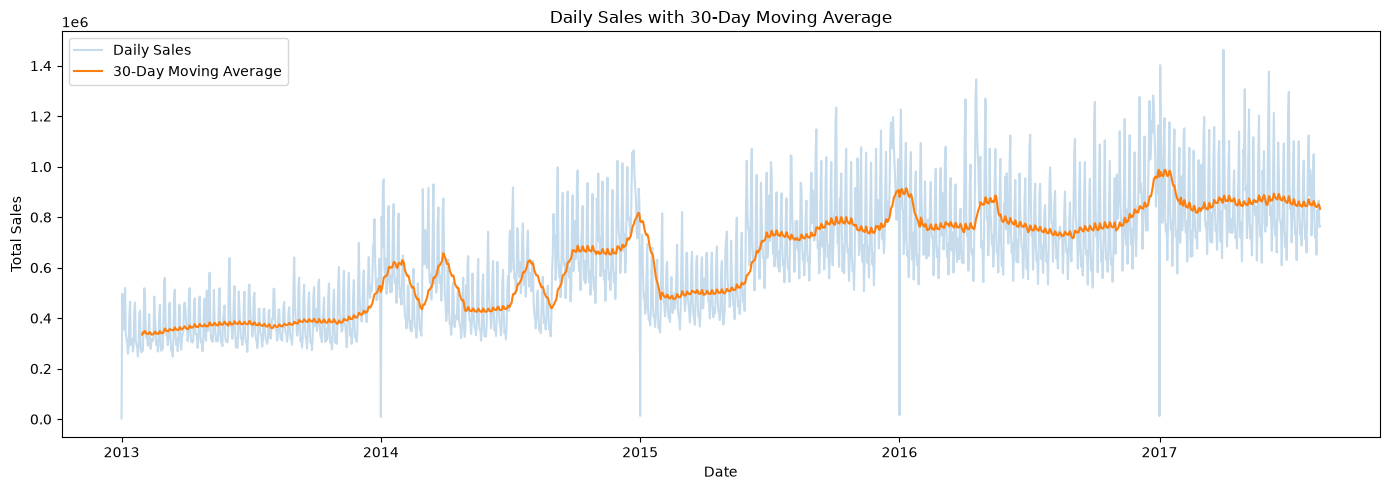

In [25]:
daily_sales = (
    train.groupby("date")["sales"]
    .sum()
    .reset_index()
)

daily_sales["MA_30"] = (
    daily_sales["sales"]
    .rolling(window=30)
    .mean()
)

plt.figure(figsize=(14, 5))

plt.plot(
    daily_sales["date"],
    daily_sales["sales"],
    alpha=0.25,
    label="Daily Sales"
)

plt.plot(
    daily_sales["date"],
    daily_sales["MA_30"],
    label="30-Day Moving Average"
)

plt.title("Daily Sales with 30-Day Moving Average")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.legend()
plt.tight_layout()
plt.show()

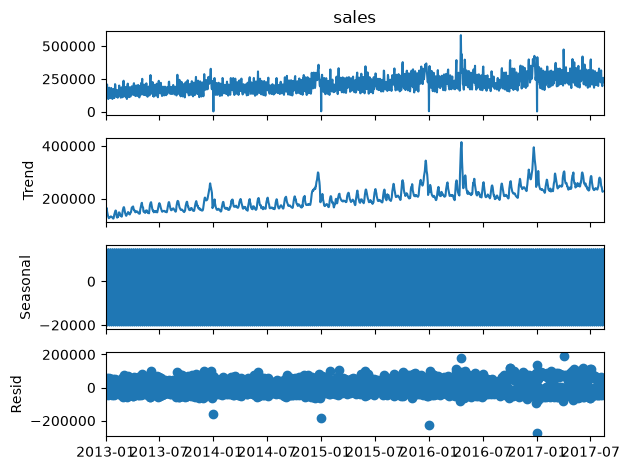

In [26]:
from statsmodels.tsa.seasonal import seasonal_decompose

grocery = (
    model_data[model_data["family"] == "GROCERY I"]
    .set_index("date")["sales"]
)

result = seasonal_decompose(
    grocery,
    model="additive",
    period=7
)

result.plot()
plt.tight_layout()
plt.show()